# Electrocatalysis (J): analysis

All results of the experiment in one place. Read [README.md](README.md) first for the question, the data and how to rerun.

**Terms used below**
- **Paper-out**: leave one paper out. Every material is predicted by a model that never saw its paper. This is the honest test.
- **Random**: repeated 5-fold over materials. Siblings from the same paper end up in training, so it overstates performance.
- **Method**: how J is corrected for the paper (batch) effect before training: `none`, `center`, `zscore`, `combat`, `mixed`. See `corrections.py`.
- **Tables**: feature set × approach. `ecfp`, `rf_best` (EState + functional groups), `brr_best` (descriptor + ECFP + EState + FG), `maccs`; `a1_full` = whole monomers, `a2_main_side` = main ‖ side, `a3_all` = both.
- **R² abs**: R² of J. **R² within**: R² of the deviations from each paper's mean. **WPA**: within-paper pairwise accuracy, i.e. the share of same-paper pairs ordered correctly (0.5 = chance, 95% CI from a bootstrap over papers).
- **Subsets**: `all` (55 materials) and `clean` (49, without the 6 suspect rows flagged by `clean.py`).

In [1]:
import os
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

if os.path.basename(os.getcwd()) == "electrocatalysis":
    os.chdir("../..")  # run relative to the repo root
from experiments.electrocatalysis.common import MODEL_NAMES, load_config, metrics, paper_pairs
from experiments.electrocatalysis.corrections import METHODS

config = load_config()
WORK_DIR = config["work_dir"]
APPROACHES = ["a1_full", "a2_main_side", "a3_all"]
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
rng = np.random.default_rng(0)

preds = pd.concat([pd.read_csv(p) for p in glob(os.path.join(WORK_DIR, "runs", "*", "*", "*", "*", "*", "predictions.csv"))], ignore_index=True)
preds["model_name"] = preds["model"].map(MODEL_NAMES)
KEYS = ["subset", "cv", "method", "model", "feature_set", "approach"]

# random CV predicts every material once per repeat: score each repeat, then average
res = (preds.groupby(KEYS + ["repeat"]).apply(lambda g: metrics(g, rng, n_boot=200), include_groups=False)
       .groupby(KEYS).mean().reset_index())
res["model_name"] = res["model"].map(MODEL_NAMES)
print(f"{len(res)} configurations")

624 configurations


## Data
Every change `clean.py` made to the spreadsheet, and the rows kept but flagged as suspect.

In [2]:
pd.read_csv("experiments/electrocatalysis/data/corrections.csv")[["number", "column", "reason", "confidence"]]

,number,column,reason,confidence
0,57,smiles_2,hydrazide written as ONN,medium
1,58,smiles_2,hydrazide written as ONN,medium
2,59,smiles_2,hydrazide written as ONN,medium
3,59,smiles_2,removed counter-ion,high
4,28,smiles_2,broken aromatic drawing; same skeleton drawn c...,high
5,38,smiles_1,broken aromatic drawing; same skeleton drawn c...,high
6,39,smiles_1,broken aromatic drawing; same skeleton drawn c...,high
7,41,smiles_1,broken aromatic drawing; same skeleton drawn c...,high
8,67,smiles_1,"broken aromatic drawing, no unique correct mat...",unfixed


In [3]:
data = pd.read_csv(os.path.join(WORK_DIR, "data.csv"))
print(f"{len(data)} materials, {data['paper'].nunique()} papers, {data['has_side_chain'].sum()} with side chains")
data.loc[data["suspect"].notna(), ["number", "name", "paper", "j", "suspect"]]

55 materials, 27 papers, 28 with side chains


,number,name,paper,j,suspect
8,22,NaN,Kim2018,-4.95,labelled CTF but the monomer has no nitrile group
14,28,NaN,Li2025a,-3.25,nitrile + aldehyde pair; the other rows of Li2...
36,50,TB-TD-COF,Huang2023,-2.65,tri-bromide + dialdehyde pair; sibling rows 48...
39,53,imine-COF,Yang2025,-3.60,imine-COF with a carboxylic acid monomer; look...
40,54,amide-COF,Yang2025,-4.30,amide-COF with an aldehyde monomer; looks swap...
53,67,COF-JLU82,Jia2022,-4.55,"broken aromatic drawing, not fixed"


## 1. A random split overstates what the models learn
R² of J for raw J (`none`), whole monomers (`a1_full`), all rows. The random split lets a model recognise a material's paper; leave-paper-out does not.

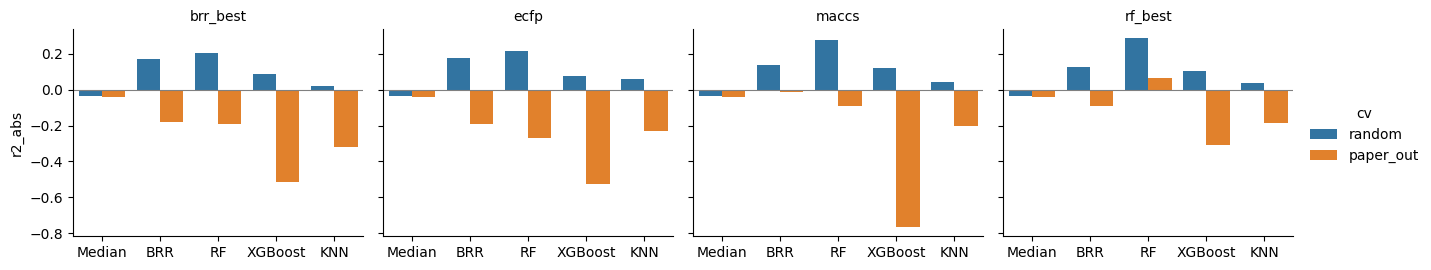

cv                      paper_out  random
feature_set model_name                   
brr_best    BRR            -0.181   0.169
            KNN            -0.320   0.020
            Median         -0.043  -0.038
            RF             -0.192   0.202
            XGBoost        -0.512   0.088
ecfp        BRR            -0.192   0.177
            KNN            -0.228   0.061
            Median         -0.043  -0.038
            RF             -0.272   0.217
            XGBoost        -0.527   0.076
maccs       BRR            -0.012   0.135
            KNN            -0.204   0.044
            Median         -0.043  -0.038
            RF             -0.091   0.278
            XGBoost        -0.763   0.119
rf_best     BRR            -0.093   0.124
            KNN            -0.184   0.034
            Median         -0.043  -0.038
            RF              0.065   0.284
            XGBoost        -0.306   0.101

In [4]:
r = res[(res["subset"] == "all") & (res["method"] == "none") & (res["approach"] == "a1_full")]
g = sns.catplot(data=r, x="model_name", y="r2_abs", hue="cv", col="feature_set", kind="bar", height=3, aspect=1.1,
                order=["Median", "BRR", "RF", "XGBoost", "KNN"], hue_order=["random", "paper_out"])
for ax in g.axes.flat:
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel("")
g.set_titles("{col_name}")
plt.show()
r.pivot_table(index=["feature_set", "model_name"], columns="cv", values="r2_abs").round(3)

## 2. Paper correction helps ranking within a paper, not absolute J
Leave-paper-out only. Each dot is one model × feature table; the bar is the mean. Left: within-paper accuracy. Right: R² of J for an unseen paper.

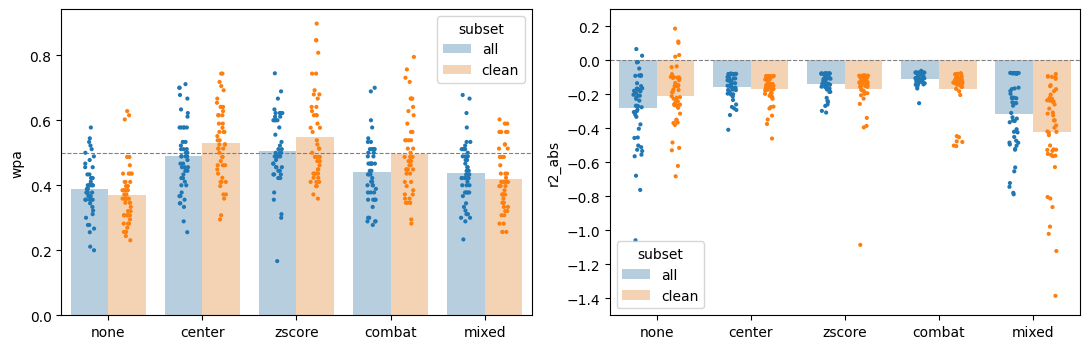

wpa        r2_within        r2_abs       
subset    all  clean       all  clean    all  clean
method                                             
center  0.489  0.531    -0.142 -0.061 -0.157 -0.173
combat  0.441  0.495    -0.092 -0.048 -0.111 -0.168
mixed   0.438  0.420    -0.604 -0.466 -0.319 -0.422
none    0.390  0.371    -1.029 -0.922 -0.281 -0.210
zscore  0.506  0.549    -0.113 -0.011 -0.140 -0.169

In [5]:
po = res[(res["cv"] == "paper_out") & (res["model"] != "median")]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, ref in [(axes[0], "wpa", 0.5), (axes[1], "r2_abs", 0.0)]:
    sns.barplot(data=po, x="method", y=metric, hue="subset", order=METHODS, errorbar=None, alpha=0.35, ax=ax)
    sns.stripplot(data=po, x="method", y=metric, hue="subset", order=METHODS, dodge=True, size=3, ax=ax, legend=False)
    ax.axhline(ref, color="grey", lw=0.8, ls="--")
    ax.set_xlabel("")
axes[1].set_ylim(-1.5, 0.3)
plt.tight_layout()
plt.show()
po.groupby(["subset", "method"])[["wpa", "r2_within", "r2_abs"]].mean().round(3).unstack("subset")

### Paired comparison with `none`
For each model × feature table: change in within-paper accuracy when the correction is used, with a 95% interval from resampling the same papers for both. `better` / `worse` count the intervals fully above / below zero.

In [6]:
def paired(a: pd.DataFrame, b: pd.DataFrame, n_boot: int = 1000) -> pd.Series:
    pa = paper_pairs(a).groupby("paper")["score"].agg(["sum", "count"])
    pb = paper_pairs(b).groupby("paper")["score"].agg(["sum", "count"])
    pa, pb = pa.align(pb, join="inner", axis=0)
    idx = rng.integers(0, len(pa), size=(n_boot, len(pa)))
    wa = pa["sum"].to_numpy()[idx].sum(1) / pa["count"].to_numpy()[idx].sum(1)
    wb = pb["sum"].to_numpy()[idx].sum(1) / pb["count"].to_numpy()[idx].sum(1)
    d = wb - wa
    return pd.Series({"diff": pb["sum"].sum() / pb["count"].sum() - pa["sum"].sum() / pa["count"].sum(), "lo": np.percentile(d, 2.5), "hi": np.percentile(d, 97.5)})


po_preds = preds[(preds["cv"] == "paper_out") & (preds["model"] != "median")]
rows = []
for (subset, model, fs, approach), g in po_preds.groupby(["subset", "model", "feature_set", "approach"]):
    for method in METHODS[1:]:
        rows.append({"subset": subset, "model": model, "feature_set": fs, "approach": approach, "method": method} | paired(g[g["method"] == "none"], g[g["method"] == method]).to_dict())
vs_none = pd.DataFrame(rows)
vs_none.groupby(["subset", "method"]).agg(mean_diff=("diff", "mean"), better=("lo", lambda s: (s > 0).sum()), worse=("hi", lambda s: (s < 0).sum()), n=("diff", "size")).round(3)

mean_diff  better  worse   n
subset method                              
all    center      0.100       3      0  48
       combat      0.051       1      1  48
       mixed       0.048       4      0  48
       zscore      0.117       6      0  48
clean  center      0.160      11      0  48
       combat      0.124       9      0  48
       mixed       0.049       1      1  48
       zscore      0.178       8      0  48

## 3. Best configurations and the permutation test

In [7]:
best = res[(res["cv"] == "paper_out") & (res["model"] != "median")].sort_values("wpa", ascending=False)
best.groupby("subset").head(6)[["subset", "method", "model_name", "feature_set", "approach", "wpa", "wpa_lo", "wpa_hi", "r2_within", "r2_abs"]].round(3)

,subset,method,model_name,feature_set,approach,wpa,wpa_lo,wpa_hi,r2_within,r2_abs
545,clean,zscore,RF,ecfp,a3_all,0.897,0.809,1.000,0.176,-0.117
543,clean,zscore,RF,ecfp,a1_full,0.846,0.760,0.976,0.170,-0.121
544,clean,zscore,RF,ecfp,a2_main_side,0.846,0.782,0.958,0.146,-0.132
557,clean,zscore,XGBoost,ecfp,a3_all,0.808,0.619,0.934,0.154,-0.195
396,clean,combat,XGBoost,brr_best,a1_full,0.795,0.600,0.917,0.130,-0.077
399,clean,combat,XGBoost,ecfp,a1_full,0.756,0.587,0.883,0.191,-0.098
211,all,zscore,BRR,maccs,a2_main_side,0.744,0.519,0.861,0.001,-0.079
8,all,center,BRR,maccs,a3_all,0.711,0.481,0.822,0.005,-0.084
7,all,center,BRR,maccs,a2_main_side,0.700,0.483,0.833,0.005,-0.083
55,all,combat,BRR,maccs,a2_main_side,0.700,0.540,0.813,0.004,-0.074


`permutation.py` shuffles J inside each paper 100 times for the top configurations per subset and reruns them. `p_value` is the share of shuffles that reach the observed accuracy (minimum 1/101). The configurations were picked as the best of many, which these p-values do not account for.

In [8]:
pd.read_csv(os.path.join(WORK_DIR, "permutation.csv")).round(3)

,subset,method,model,approach,feature_set,observed,null_mean,null_95,p_value
0,clean,zscore,random_forest,a3_all,ecfp,0.897,0.502,0.667,0.01
1,clean,zscore,random_forest,a1_full,ecfp,0.846,0.481,0.668,0.01
2,clean,zscore,random_forest,a2_main_side,ecfp,0.846,0.501,0.642,0.01
3,all,zscore,bayes,a2_main_side,maccs,0.744,0.490,0.678,0.01
4,all,center,bayes,a3_all,maccs,0.711,0.506,0.646,0.04
5,all,combat,bayes,a2_main_side,maccs,0.700,0.519,0.678,0.04


## 4. Does the main/side split help?
Change in within-paper accuracy of `a2_main_side` and `a3_all` against `a1_full`, same model, feature set and correction method.

In [9]:
rows = []
for (subset, method, model, fs), g in po_preds.groupby(["subset", "method", "model", "feature_set"]):
    for approach in APPROACHES[1:]:
        rows.append({"subset": subset, "method": method, "model": model, "feature_set": fs, "vs_a1": approach} | paired(g[g["approach"] == "a1_full"], g[g["approach"] == approach]).to_dict())
split = pd.DataFrame(rows)
split.groupby(["subset", "method", "vs_a1"]).agg(mean_diff=("diff", "mean"), better=("lo", lambda s: (s > 0).sum()), worse=("hi", lambda s: (s < 0).sum()), n=("diff", "size")).round(3).unstack("vs_a1")

mean_diff              better               worse                   n       
vs_a1         a2_main_side a3_all a2_main_side a3_all a2_main_side a3_all a2_main_side a3_all
subset method                                                                                
all    center        0.036  0.004            1      1            0      2           16     16
       combat        0.052  0.025            0      2            0      0           16     16
       mixed         0.049  0.044            0      2            0      0           16     16
       none         -0.010 -0.009            0      0            0      1           16     16
       zscore        0.069  0.065            2      3            0      0           16     16
clean  center        0.023  0.019            1      2            0      0           16     16
       combat       -0.014 -0.004            1      0            0      0           16     16
       mixed         0.072  0.033            1      1            0      0           16     16
       none         -0.008 -0.003            0      1            2      0           16     16
       zscore        0.030  0.037            0      0            0      0           16     16

## 5. Which part of the molecule do the models use?
Share of mean |SHAP| per block (whole monomers, main chain, side chain), leave-paper-out with the `zscore` correction, all rows.
Feature names starting with `main_` / `side_` belong to those blocks; MACCS uses `full_` / `main_` / `side_`.

In [10]:
def block(feature: str) -> str:
    if feature == "is_ctf":
        return "is_ctf"
    return "main" if feature.startswith("main_") else "side" if feature.startswith("side_") else "full"


shares = []
for path in glob(os.path.join(WORK_DIR, "runs", "all", "paper_out", "zscore", "*", "*", "importance.csv")):
    imp = pd.read_csv(path)
    model, table = path.split(os.sep)[-3], path.split(os.sep)[-2]
    s = imp.groupby(imp["feature"].map(block))["mean_abs_shap"].sum()
    shares.append((s / s.sum()).rename((MODEL_NAMES[model], *table.split("__")[::-1])))
pd.DataFrame(shares).sort_index().round(2)

feature                        full  is_ctf  main  side
BRR     brr_best a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.65  0.35
                 a3_all        0.43     0.0  0.37  0.20
        ecfp     a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.68  0.32
                 a3_all        0.43     0.0  0.39  0.18
        maccs    a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.34  0.66
                 a3_all        0.42     0.0  0.20  0.38
        rf_best  a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.59  0.41
                 a3_all        0.46     0.0  0.32  0.22
RF      brr_best a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.83  0.17
                 a3_all        0.49     0.0  0.44  0.07
        ecfp     a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.86  0.14
                 a3_all        0.48     0.0  0.47  0.05
        maccs    a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.72  0.28
                 a3_all        0.50     0.0  0.33  0.17
        rf_best  a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.76  0.24
                 a3_all        0.48     0.0  0.43  0.08
XGBoost brr_best a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.85  0.15
                 a3_all        0.74     0.0  0.23  0.03
        ecfp     a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.87  0.13
                 a3_all        0.77     0.0  0.22  0.01
        maccs    a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.72  0.28
                 a3_all        0.73     0.0  0.12  0.15
        rf_best  a1_full       1.00     0.0   NaN   NaN
                 a2_main_side   NaN     0.0  0.79  0.21
                 a3_all        0.66     0.0  0.30  0.04

## 6. The final model for explainability
`final_model.py` fits the configuration in `config.yaml` (`final_model`) on all papers of its subset and saves the model, SHAP values and the substructures behind each ECFP bit. A positive `direction` means more of the feature pushes J up (less negative, a worse catalyst).

In [11]:
fm = config["final_model"]
fm_dir = os.path.join(WORK_DIR, "final_model", f"{fm['subset']}__{fm['method']}__{fm['model']}__{fm['table']}")
imp = pd.read_csv(os.path.join(fm_dir, "importance.csv"))
bits_path = os.path.join(fm_dir, "ecfp_bits.csv")
if os.path.exists(bits_path):
    imp = imp.merge(pd.read_csv(bits_path)[["feature", "substructures"]], on="feature", how="left")
print(fm_dir)
imp.head(15).round(3)

experiments/electrocatalysis/results/final_model/clean__zscore__random_forest__a1_full__ecfp


,feature,mean_abs_shap,mean_shap,direction,n_materials_with_feature,substructures
0,ecfp_136,0.184,0.008,-0.340,23,c(-c)(c)c [r1] (23)
1,ecfp_350,0.102,0.006,-0.979,6,c(C)(c)c [r1] (3) | c(c(-c)c)c(c)n [r2] (2) | ...
2,ecfp_361,0.068,-0.002,-0.780,14,c(-c)(n)n [r1] (8) | c(C)(c)c [r1] (5) | C(#N)...
3,ecfp_726,0.066,0.010,0.281,33,c(c)c [r1] (33)
4,ecfp_356,0.054,-0.009,-0.387,39,C [r0] (39)
5,ecfp_486,0.048,-0.000,-0.900,10,O(C)CC [r2] (7) | C(c)(N)=O [r1] (7)
6,ecfp_896,0.034,0.002,0.191,21,c(cc)c(-c)c [r2] (21)
7,ecfp_80,0.032,-0.007,-0.532,11,C [r0] (7) | N(N)C(c)=O [r2] (7) | c(nc)c(C)c ...
8,ecfp_704,0.030,0.005,-0.983,3,c(OC)(cc)c(C)c [r2] (3)
9,ecfp_849,0.027,-0.003,-0.103,37,C [r0] (37)
